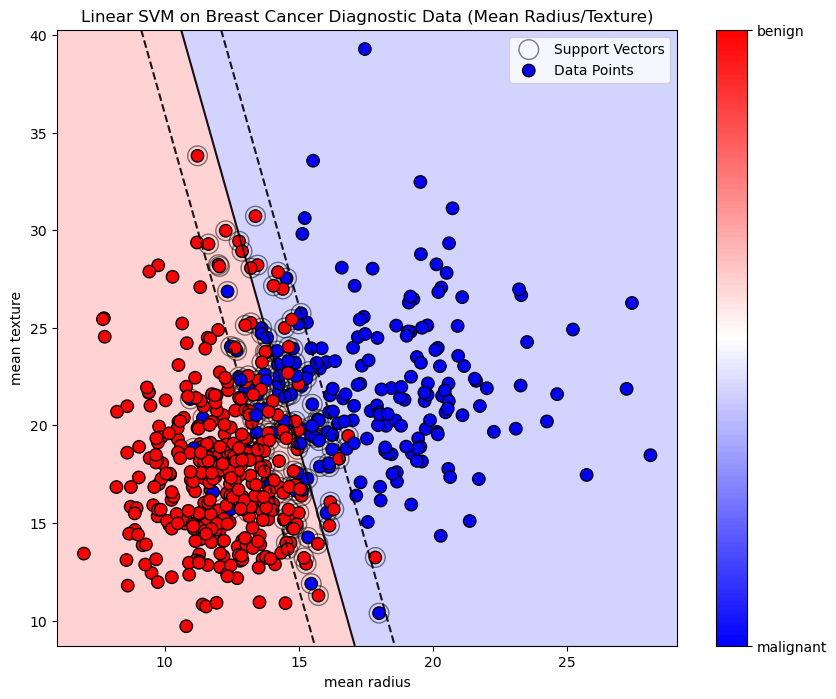

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets
from sklearn.svm import SVC

# 1. Load Dataset (Breast Cancer, first 2 features for 2D plotting)
# X: mean radius, mean texture
# y: 0=malignant, 1=benign
cancer = datasets.load_breast_cancer()
X = cancer.data[:, :2]
y = cancer.target

# 2. Train Model
# kernel='linear' focuses on finding a straight separating line
# C=1.0 is standard margin penalization
clf = SVC(kernel='linear', C=1.0, random_state=42)
clf.fit(X, y)

# 3. Create Plots
# Setup mesh for decision regions
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

# Predict on mesh and reshape
Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(10, 8))
plt.contourf(xx, yy, Z, cmap='bwr', alpha=0.2) # Decision areas in light colors

# Highlight Support Vectors
support_vectors = clf.support_vectors_
plt.scatter(support_vectors[:, 0], support_vectors[:, 1],
            s=200, facecolors='none', edgecolors='k', label='Support Vectors', alpha=0.5)

# Plot Data Points
formatter = plt.FuncFormatter(lambda i, *args: cancer.target_names[int(i)])
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='bwr', edgecolor='k', s=80, label='Data Points')
plt.colorbar(ticks=[0, 1], format=formatter)

# Plot Decision Hyperplane (Decision Boundary)
ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

xx_db = np.linspace(xlim[0], xlim[1], 30)
yy_db = np.linspace(ylim[0], ylim[1], 30)
YY_db, XX_db = np.meshgrid(yy_db, xx_db)
xy_db = np.vstack([XX_db.ravel(), YY_db.ravel()]).T
Z_db = clf.decision_function(xy_db).reshape(XX_db.shape)

# Plot decision boundary and margins
ax.contour(XX_db, YY_db, Z_db, colors='k', levels=[-1, 0, 1], alpha=0.9,
           linestyles=['--', '-', '--'])

plt.xlabel(cancer.feature_names[0])
plt.ylabel(cancer.feature_names[1])
plt.title('Linear SVM on Breast Cancer Diagnostic Data (Mean Radius/Texture)')
plt.legend()
plt.show()